<a href="https://colab.research.google.com/github/shashira/-talk-to-my-friend-bot/blob/master/HW10_RAG_Reranking_Chunking_Memory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 10 — Improving RAG with Reranking, Chunking, and Conversational Memory

This notebook implements and evaluates a Retrieval-Augmented Generation system
using the first 100 documents from the document subset of the
ccdv/arxiv-summarization dataset.

The experiments compare:

1. Two chunking strategies
2. Retrieval without reranking
3. Retrieval with cross-encoder reranking
4. Conversational retrieval with memory
5. Precision@K, Recall@K, and MRR

In [1]:
# ============================================================
# Homework 10 — Personal Parameters and Reproducibility
# ============================================================

import random
import numpy as np
import torch

# Personal parameters
SID4 = 8811
SEED = SID4

SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

# Set random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select the available device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("SID4  =", SID4)
print("SEED  =", SEED)
print("SLICE =", SLICE)
print("HP_ID =", HP_ID)
print("CLS_A =", CLS_A)
print("CLS_B =", CLS_B)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not available. CPU will be used.")

SID4  = 8811
SEED  = 8811
SLICE = 811
HP_ID = 3
CLS_A = 1
CLS_B = 0
Device: cuda
GPU: Tesla T4


###Interpretation

This cell records the required personal parameters and initializes the random seeds. Using the same seed makes the dataset processing, document ordering, chunk creation, embedding generation, and evaluation as reproducible as possible.

## Step 1 — Install Libraries and Import Packages

In [3]:
import chromadb
import datasets
import sentence_transformers
import langchain_chroma
import langchain_huggingface

print("Libraries imported successfully.")
print("Device:", device)

Libraries imported successfully.
Device: cuda


In [4]:
# ============================================================
# Imports and Basic Configuration
# ============================================================

import os
import re
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from tqdm.auto import tqdm

from sentence_transformers import CrossEncoder

from langchain_core.documents import Document
from langchain_text_splitters import (
    RecursiveCharacterTextSplitter
)

from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings

print("Libraries imported successfully.")
print("Device:", device)

Libraries imported successfully.
Device: cuda


###Interpretation

This cell installs and imports the components needed to build the RAG system.
- datasets loads the ArXiv summarization data.
- RecursiveCharacterTextSplitter creates document chunks.
- HuggingFaceEmbeddings converts chunks into vectors.
- Chroma stores and searches the vectors.
- CrossEncoder performs reranking after the initial vector search.
- pandas stores the retrieval results and evaluation metrics in tables.

## Step 2 — Load the ArXiv Summarization Dataset

The assignment requires the `document` configuration and the first 100 documents from the training split.

In [5]:
# ============================================================
# Load the First 100 Training Documents
# ============================================================

DATASET_NAME = "ccdv/arxiv-summarization"
DATASET_CONFIGURATION = "document"
NUMBER_OF_DOCUMENTS = 100

arxiv_dataset = load_dataset(
    DATASET_NAME,
    DATASET_CONFIGURATION,
    split=f"train[:{NUMBER_OF_DOCUMENTS}]"
)

print("Dataset loaded successfully.")
print("Dataset configuration:", DATASET_CONFIGURATION)
print("Number of documents:", len(arxiv_dataset))
print("Available columns:", arxiv_dataset.column_names)

README.md:   0%|          | 0.00/3.96k [00:00<?, ?B/s]

document/train-00000-of-00015.parquet: reconstructing file:   0%|          |  0.00B /  227MB            

document/train-00000-of-00015.parquet: downloading bytes:           |  0.00B            

document/train-00001-of-00015.parquet: reconstructing file:   0%|          |  0.00B /  226MB            

document/train-00001-of-00015.parquet: downloading bytes:           |  0.00B            

document/train-00002-of-00015.parquet: reconstructing file:   0%|          |  0.00B /  226MB            

... (29 outputs left out)

Generating train split:   0%|          | 0/203037 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/6436 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/6440 [00:00<?, ? examples/s]

Dataset loaded successfully.
Dataset configuration: document
Number of documents: 100
Available columns: ['article', 'abstract']


In [6]:
# ============================================================
# Inspect One Dataset Example
# ============================================================

first_example = arxiv_dataset[0]

print("Columns in the first example:")
for column_name, value in first_example.items():
    if isinstance(value, str):
        print(f"\n{column_name}:")
        print(value[:500])
    else:
        print(f"\n{column_name}: {value}")

Columns in the first example:

article:
additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models . it is well - known that good estimators in additive models are in general less prone to the curse of high dimensionality than good estimators in fully nonparametric models .

abstract:
additive models play an important role in semiparametric statistics . 
 this paper gives learning rates for regularized kernel based methods for additive models . 
 these learning rates compare favourably in particular in high dimensions to recent results on optimal learning rates for purely nonparametric regularized kernel based quantile regression using the gaussian radial basis function kernel , provided the assumption of an additive model i

In [7]:
# ============================================================
# Identify the Document and Summary Columns
# ============================================================

# The dataset normally stores the full paper text in "article"
# and the reference summary in "abstract".
possible_document_columns = [
    "article",
    "document",
    "text",
    "source"
]

possible_summary_columns = [
    "abstract",
    "summary",
    "target"
]

document_column = next(
    (
        column_name
        for column_name in possible_document_columns
        if column_name in arxiv_dataset.column_names
    ),
    None
)

summary_column = next(
    (
        column_name
        for column_name in possible_summary_columns
        if column_name in arxiv_dataset.column_names
    ),
    None
)

if document_column is None:
    raise ValueError(
        "Could not identify the full-document text column."
    )

if summary_column is None:
    raise ValueError(
        "Could not identify the summary column."
    )

print("Document text column:", document_column)
print("Summary column:", summary_column)

Document text column: article
Summary column: abstract


### Convert the Dataset into LangChain Documents

Each source document is converted into a LangChain `Document`. The document ID and reference abstract are stored as metadata so that retrieved chunks can be evaluated later.

In [8]:
# ============================================================
# Convert Dataset Records to LangChain Documents
# ============================================================

source_documents = []

for document_id, row in enumerate(arxiv_dataset):

    document_text = row[document_column]
    reference_summary = row[summary_column]

    source_document = Document(
        page_content=document_text,
        metadata={
            "document_id": document_id,
            "source": DATASET_NAME,
            "dataset_configuration": DATASET_CONFIGURATION,
            "reference_summary": reference_summary
        }
    )

    source_documents.append(source_document)

print("Number of LangChain documents:", len(source_documents))
print("First document ID:", source_documents[0].metadata["document_id"])
print("First document character count:", len(
    source_documents[0].page_content
))
print("\nFirst document preview:")
print(source_documents[0].page_content[:1000])

Number of LangChain documents: 100
First document ID: 0
First document character count: 26092

First document preview:
additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models . it is well - known that good estimators in additive models are in general less prone to the curse of high dimensionality than good estimators in fully nonparametric models . many examples of such estimators belong to the large class of regularized kernel based methods over a reproducing kernel hilbert space @xmath0 , see e.g. @xcite . in the last years many interesting results on learning rates of regularized kernel based models for additive models have been published when the focus is on sparsity and when the classical least squares loss function 

###Interpretation

Exactly 100 documents were loaded from the training split using the required document configuration. Each document contains the full scientific paper text and its reference abstract.

The full document text will be split into chunks later. The document_id metadata will allow us to identify which original paper produced each retrieved chunk. The reference abstract is also preserved for later qualitative analysis.

## Step 3 — Chunking Strategies

Two chunking strategies are used:

1. Strategy 1 — Recursive character chunks  
   Chunk size: 500 characters  
   Overlap: 50 characters

2. Strategy 2 — Sentence-aware chunks  
   Maximum size: approximately 1,000 characters  
   Overlap: one sentence

The first strategy uses fixed character boundaries. The second tries to keep complete sentences together so that important scientific context is less likely to be split in the middle of a sentence.

In [9]:
# ============================================================
# Chunking Strategy 1: Recursive Character Splitting
# ============================================================

STRATEGY_1_CHUNK_SIZE = 500
STRATEGY_1_CHUNK_OVERLAP = 50

strategy_1_splitter = RecursiveCharacterTextSplitter(
    chunk_size=STRATEGY_1_CHUNK_SIZE,
    chunk_overlap=STRATEGY_1_CHUNK_OVERLAP,
    separators=["\n\n", "\n", ". ", " ", ""]
)

strategy_1_chunks = strategy_1_splitter.split_documents(
    source_documents
)

for chunk_id, chunk in enumerate(strategy_1_chunks):
    chunk.metadata["chunk_strategy"] = "recursive_500_50"
    chunk.metadata["chunk_id"] = chunk_id

print("Strategy 1: Recursive character chunking")
print("Chunk size:", STRATEGY_1_CHUNK_SIZE)
print("Chunk overlap:", STRATEGY_1_CHUNK_OVERLAP)
print("Total chunks:", len(strategy_1_chunks))
print("First chunk length:", len(strategy_1_chunks[0].page_content))
print("\nFirst chunk preview:")
print(strategy_1_chunks[0].page_content[:800])

Strategy 1: Recursive character chunking
Chunk size: 500
Chunk overlap: 50
Total chunks: 9093
First chunk length: 498

First chunk preview:
additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models . it is well - known that good estimators in additive models are in general less prone to the curse of high dimensionality than good estimators in fully nonparametric models


In [10]:
# ============================================================
# Chunking Strategy 2: Sentence-Aware Chunking
# ============================================================

STRATEGY_2_MAX_CHARACTERS = 1000
STRATEGY_2_SENTENCE_OVERLAP = 1


def split_into_sentences(text):
    """
    Split text into sentence-like units while preserving
    sentence-ending punctuation.
    """
    sentences = re.split(
        r"(?<=[.!?])\s+",
        text.strip()
    )

    return [
        sentence.strip()
        for sentence in sentences
        if sentence.strip()
    ]


def create_sentence_aware_chunks(
    source_document,
    maximum_characters=1000,
    sentence_overlap=1
):
    """
    Create chunks by grouping complete sentences until the
    maximum character limit is reached.

    The final sentence from the previous chunk is repeated
    in the next chunk to preserve local context.
    """
    sentences = split_into_sentences(
        source_document.page_content
    )

    sentence_chunks = []
    current_sentences = []
    current_length = 0

    for sentence in sentences:

        proposed_length = (
            current_length
            + len(sentence)
            + (1 if current_sentences else 0)
        )

        if (
            current_sentences
            and proposed_length > maximum_characters
        ):
            sentence_chunks.append(
                " ".join(current_sentences)
            )

            overlap_sentences = current_sentences[
                -sentence_overlap:
            ]

            current_sentences = list(overlap_sentences)
            current_length = sum(
                len(item)
                for item in current_sentences
            )

        current_sentences.append(sentence)
        current_length = (
            current_length
            + len(sentence)
            + (1 if len(current_sentences) > 1 else 0)
        )

    if current_sentences:
        sentence_chunks.append(
            " ".join(current_sentences)
        )

    output_documents = []

    for chunk_id, chunk_text in enumerate(sentence_chunks):
        chunk_metadata = dict(source_document.metadata)
        chunk_metadata["chunk_strategy"] = (
            "sentence_aware_1000_overlap_1_sentence"
        )
        chunk_metadata["chunk_id"] = chunk_id

        output_documents.append(
            Document(
                page_content=chunk_text,
                metadata=chunk_metadata
            )
        )

    return output_documents


strategy_2_chunks = []

for source_document in source_documents:
    strategy_2_chunks.extend(
        create_sentence_aware_chunks(
            source_document,
            maximum_characters=STRATEGY_2_MAX_CHARACTERS,
            sentence_overlap=STRATEGY_2_SENTENCE_OVERLAP
        )
    )

print("Strategy 2: Sentence-aware chunking")
print("Maximum characters:", STRATEGY_2_MAX_CHARACTERS)
print("Sentence overlap:", STRATEGY_2_SENTENCE_OVERLAP)
print("Total chunks:", len(strategy_2_chunks))
print("First chunk length:", len(strategy_2_chunks[0].page_content))
print("\nFirst chunk preview:")
print(strategy_2_chunks[0].page_content[:800])

Strategy 2: Sentence-aware chunking
Maximum characters: 1000
Sentence overlap: 1
Total chunks: 4812
First chunk length: 980

First chunk preview:
additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models . it is well - known that good estimators in additive models are in general less prone to the curse of high dimensionality than good estimators in fully nonparametric models . many examples of such estimators belong to the large class of regularized kernel based methods over a reproducing kernel hilbert space @xmath0 , see e.g. @xcite . in the last years many interesting results on learning rates of regularized kernel based models for additive models have been published 


In [11]:
# ============================================================
# Compare Chunking Statistics
# ============================================================

def calculate_chunk_statistics(chunks, strategy_name):
    chunk_lengths = [
        len(chunk.page_content)
        for chunk in chunks
    ]

    return {
        "Strategy": strategy_name,
        "Number of chunks": len(chunks),
        "Minimum length": min(chunk_lengths),
        "Average length": np.mean(chunk_lengths),
        "Maximum length": max(chunk_lengths)
    }


chunking_statistics = pd.DataFrame([
    calculate_chunk_statistics(
        strategy_1_chunks,
        "Recursive characters: 500/50"
    ),
    calculate_chunk_statistics(
        strategy_2_chunks,
        "Sentence-aware: max 1000/1 sentence"
    )
])

display(chunking_statistics)

,Strategy,Number of chunks,Minimum length,Average length,Maximum length
0,Recursive characters: 500/50,9093,2,404.961289,500
1,Sentence-aware: max 1000/1 sentence,4812,84,915.501455,8634


###Interpretation

Strategy 1 creates smaller fixed-size chunks using recursive character splitting. It produces focused chunks, but a sentence or idea may be divided between two chunks.

Strategy 2 groups complete sentences until the maximum size is reached and repeats one sentence between neighboring chunks. This preserves more natural scientific context, although the chunks may have different lengths.

The statistics table shows how the two strategies differ in the number and size of generated chunks. These different chunk collections will be embedded and indexed separately so their retrieval performance can be compared fairly.

## Step 4 — Create Embeddings and ChromaDB Vector Stores

Each chunk is converted into a normalized sentence embedding. The two chunking strategies are indexed separately so that their retrieval results can be compared fairly.

In [12]:
# ============================================================
# Create the Embedding Model
# ============================================================

EMBEDDING_MODEL_NAME = (
    "sentence-transformers/all-MiniLM-L6-v2"
)

embedding_device = str(device)

embedding_model = HuggingFaceEmbeddings(
    model_name=EMBEDDING_MODEL_NAME,
    model_kwargs={
        "device": embedding_device
    },
    encode_kwargs={
        "normalize_embeddings": True
    }
)

test_embedding = embedding_model.embed_query(
    "This is a test scientific sentence."
)

print("Embedding model:", EMBEDDING_MODEL_NAME)
print("Embedding device:", embedding_device)
print("Embedding dimension:", len(test_embedding))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model: sentence-transformers/all-MiniLM-L6-v2
Embedding device: cuda
Embedding dimension: 384


In [13]:
# ============================================================
# Create Separate ChromaDB Vector Stores
# ============================================================

CHROMA_STRATEGY_1_DIRECTORY = (
    "/content/chroma_hw10_strategy_1"
)

CHROMA_STRATEGY_2_DIRECTORY = (
    "/content/chroma_hw10_strategy_2"
)

# Create a vector store for Strategy 1
strategy_1_vector_store = Chroma.from_documents(
    documents=strategy_1_chunks,
    embedding=embedding_model,
    collection_name="hw10_recursive_500_50",
    persist_directory=CHROMA_STRATEGY_1_DIRECTORY
)

# Create a vector store for Strategy 2
strategy_2_vector_store = Chroma.from_documents(
    documents=strategy_2_chunks,
    embedding=embedding_model,
    collection_name="hw10_sentence_aware_1000",
    persist_directory=CHROMA_STRATEGY_2_DIRECTORY
)

print("Strategy 1 ChromaDB collection created.")
print("Strategy 1 indexed chunks:", len(strategy_1_chunks))

print("\nStrategy 2 ChromaDB collection created.")
print("Strategy 2 indexed chunks:", len(strategy_2_chunks))

Strategy 1 ChromaDB collection created.
Strategy 1 indexed chunks: 9093

Strategy 2 ChromaDB collection created.
Strategy 2 indexed chunks: 4812


In [14]:
# ============================================================
# Create Vector Retrievers
# ============================================================

RETRIEVAL_K = 5

strategy_1_retriever = strategy_1_vector_store.as_retriever(
    search_type="similarity",
    search_kwargs={
        "k": RETRIEVAL_K
    }
)

strategy_2_retriever = strategy_2_vector_store.as_retriever(
    search_type="similarity",
    search_kwargs={
        "k": RETRIEVAL_K
    }
)

print("Retrievers created successfully.")
print("Initial retrieval K:", RETRIEVAL_K)

Retrievers created successfully.
Initial retrieval K: 5


###Interpretation

The embedding model converts every chunk into a 384-dimensional vector. Normalized embeddings make cosine similarity comparisons consistent.

Two separate ChromaDB collections were created:
- Strategy 1: recursive 500-character chunks with 50-character overlap
- Strategy 2: sentence-aware chunks with a maximum of approximately 1,000 characters
Keeping the collections separate allows the same query to be evaluated under both chunking strategies. The retrievers initially return the top five chunks based only on vector similarity. Reranking will be added later as a second-stage retrieval step.

## Step 5 — Initial Retrieval Without Reranking

The first retrieval stage uses only embedding similarity. No cross-encoder reranker is used yet.

The same queries will be sent to both ChromaDB collections so that the chunking strategies can be compared fairly.

In [15]:
# ============================================================
# Define Sample Queries
# ============================================================

sample_queries = [
    (
        "How do attention mechanisms improve neural network "
        "sequence modeling?"
    ),
    (
        "How are deep learning representations learned from "
        "graph-structured data?"
    )
]

print("Number of sample queries:", len(sample_queries))

for query_number, query in enumerate(
    sample_queries,
    start=1
):
    print(f"{query_number}. {query}")

Number of sample queries: 2
1. How do attention mechanisms improve neural network sequence modeling?
2. How are deep learning representations learned from graph-structured data?


In [16]:
# ============================================================
# Similarity Retrieval Without Reranking
# ============================================================

def retrieve_without_reranking(
    vector_store,
    query,
    number_of_results=5
):
    """
    Retrieve chunks using vector similarity only.
    """
    retrieved_results = (
        vector_store.similarity_search_with_score(
            query,
            k=number_of_results
        )
    )

    formatted_results = []

    for rank, (document, similarity_score) in enumerate(
        retrieved_results,
        start=1
    ):
        formatted_results.append({
            "rank": rank,
            "document": document,
            "similarity_score": float(similarity_score),
            "document_id": document.metadata.get(
                "document_id"
            ),
            "chunk_id": document.metadata.get(
                "chunk_id"
            ),
            "chunk_strategy": document.metadata.get(
                "chunk_strategy"
            )
        })

    return formatted_results

In [17]:
# ============================================================
# Retrieve Top-5 Results Without Reranking
# ============================================================

retrieval_results_without_reranking = {}

for query_number, query in enumerate(
    sample_queries,
    start=1
):
    strategy_1_results = retrieve_without_reranking(
        strategy_1_vector_store,
        query,
        number_of_results=RETRIEVAL_K
    )

    strategy_2_results = retrieve_without_reranking(
        strategy_2_vector_store,
        query,
        number_of_results=RETRIEVAL_K
    )

    retrieval_results_without_reranking[
        (query_number, "strategy_1")
    ] = strategy_1_results

    retrieval_results_without_reranking[
        (query_number, "strategy_2")
    ] = strategy_2_results

    print("\n" + "=" * 100)
    print(f"QUERY {query_number}: {query}")
    print("=" * 100)

    for strategy_name, results in [
        ("Strategy 1 — Recursive 500/50", strategy_1_results),
        ("Strategy 2 — Sentence-aware", strategy_2_results)
    ]:
        print(f"\n{strategy_name}")

        for result in results:
            document = result["document"]

            print(
                f"\nRank: {result['rank']}"
                f" | Document ID: {result['document_id']}"
                f" | Chunk ID: {result['chunk_id']}"
                f" | Similarity score: "
                f"{result['similarity_score']:.4f}"
            )

            print("Text preview:")
            print(document.page_content[:500])


QUERY 1: How do attention mechanisms improve neural network sequence modeling?

Strategy 1 — Recursive 500/50

Rank: 1 | Document ID: 7 | Chunk ID: 515 | Similarity score: 1.1556
Text preview:
. such stp and ltp mechanisms have been often correlated to the short - term memory ( stm ) and long - term memory ( ltm ) models proposed by atkinson and shiffrin @xcite ( fig . [ drawing1](b ) ) . this psychological model partitions the human memory into an stm and an ltm . on the arrival of an input stimulus , information is first stored in the stm . however , upon frequent rehearsal , information gets transferred to the ltm

Rank: 2 | Document ID: 7 | Chunk ID: 510 | Similarity score: 1.3129
Text preview:
. such volatile or meta - stable synaptic plasticity mechanisms can lead to neuromorphic architectures where the synaptic memory can adapt itself to a changing environment since sections of the memory that have been not receiving frequent stimulus can be now erased and utilized to memorize 

###Interpretation

This stage performs the first-stage vector retrieval. Each query is converted into an embedding and compared with the embeddings stored in ChromaDB.

The top five chunks are displayed for both chunking strategies. The similarity score is useful for ranking within the vector-search stage, but it is not the same as the cross-encoder reranking score that will be introduced later.

The same query may retrieve different chunks under the two strategies because the chunk boundaries and chunk lengths are different. Strategy 1 may return more focused passages, while Strategy 2 may return larger passages containing more complete sentences and context.

## Step 6 — Retrieval with Reranking

The vector database first retrieves 10 candidate chunks. A cross-encoder then reads each query and candidate chunk together and assigns a relevance score.

The candidates are reordered by the cross-encoder score, and the top 5 reranked chunks are retained.

In [18]:
# ============================================================
# Load the Cross-Encoder Reranker
# ============================================================

RERANKER_MODEL_NAME = (
    "cross-encoder/ms-marco-MiniLM-L-6-v2"
)

reranker = CrossEncoder(
    RERANKER_MODEL_NAME,
    device=str(device)
)

RERANK_CANDIDATE_K = 10
RERANK_FINAL_K = 5

print("Reranker:", RERANKER_MODEL_NAME)
print("Candidate chunks before reranking:", RERANK_CANDIDATE_K)
print("Final chunks after reranking:", RERANK_FINAL_K)

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Reranker: cross-encoder/ms-marco-MiniLM-L-6-v2
Candidate chunks before reranking: 10
Final chunks after reranking: 5


In [19]:
# ============================================================
# Retrieve and Rerank Candidate Chunks
# ============================================================

def retrieve_with_reranking(
    vector_store,
    query,
    reranker_model,
    candidate_k=10,
    final_k=5
):
    """
    Retrieve candidate chunks using ChromaDB, then reorder
    them using a cross-encoder relevance score.
    """

    candidate_results = (
        vector_store.similarity_search_with_score(
            query,
            k=candidate_k
        )
    )

    candidate_documents = [
        document
        for document, _ in candidate_results
    ]

    query_document_pairs = [
        (query, document.page_content)
        for document in candidate_documents
    ]

    reranker_scores = reranker_model.predict(
        query_document_pairs
    )

    reranked_results = []

    for original_rank, (
        document,
        reranker_score
    ) in enumerate(
        zip(candidate_documents, reranker_scores),
        start=1
    ):
        reranked_results.append({
            "document": document,
            "original_rank": original_rank,
            "reranker_score": float(reranker_score),
            "document_id": document.metadata.get(
                "document_id"
            ),
            "chunk_id": document.metadata.get(
                "chunk_id"
            ),
            "chunk_strategy": document.metadata.get(
                "chunk_strategy"
            )
        })

    # Higher cross-encoder scores indicate greater relevance
    reranked_results.sort(
        key=lambda result: result["reranker_score"],
        reverse=True
    )

    for new_rank, result in enumerate(
        reranked_results[:final_k],
        start=1
    ):
        result["reranked_rank"] = new_rank

    return reranked_results[:final_k]

In [20]:
# ============================================================
# Rerank Results for Both Chunking Strategies
# ============================================================

retrieval_results_with_reranking = {}

for query_number, query in enumerate(
    sample_queries,
    start=1
):
    strategy_1_reranked = retrieve_with_reranking(
        strategy_1_vector_store,
        query,
        reranker,
        candidate_k=RERANK_CANDIDATE_K,
        final_k=RERANK_FINAL_K
    )

    strategy_2_reranked = retrieve_with_reranking(
        strategy_2_vector_store,
        query,
        reranker,
        candidate_k=RERANK_CANDIDATE_K,
        final_k=RERANK_FINAL_K
    )

    retrieval_results_with_reranking[
        (query_number, "strategy_1")
    ] = strategy_1_reranked

    retrieval_results_with_reranking[
        (query_number, "strategy_2")
    ] = strategy_2_reranked

    print("\n" + "=" * 100)
    print(f"QUERY {query_number}: {query}")
    print("=" * 100)

    for strategy_name, results in [
        ("Strategy 1 — Reranked", strategy_1_reranked),
        ("Strategy 2 — Reranked", strategy_2_reranked)
    ]:
        print(f"\n{strategy_name}")

        for result in results:
            document = result["document"]

            print(
                f"\nReranked rank: {result['reranked_rank']}"
                f" | Original rank: "
                f"{result['original_rank']}"
                f" | Document ID: "
                f"{result['document_id']}"
                f" | Reranker score: "
                f"{result['reranker_score']:.4f}"
            )

            print("Text preview:")
            print(document.page_content[:500])


QUERY 1: How do attention mechanisms improve neural network sequence modeling?

Strategy 1 — Reranked

Reranked rank: 1 | Original rank: 3 | Document ID: 7 | Reranker score: -6.8316
Text preview:
.    in a neuromorphic computing platform , synapses form the pathways between neurons and their strength modulate the magnitude of the signal transmitted between the neurons . the exact mechanisms that underlie the `` learning '' or `` plasticity '' of such synaptic connections are still under debate

Reranked rank: 2 | Original rank: 1 | Document ID: 7 | Reranker score: -9.2041
Text preview:
. such stp and ltp mechanisms have been often correlated to the short - term memory ( stm ) and long - term memory ( ltm ) models proposed by atkinson and shiffrin @xcite ( fig . [ drawing1](b ) ) . this psychological model partitions the human memory into an stm and an ltm . on the arrival of an input stimulus , information is first stored in the stm . however , upon frequent rehearsal , information ge

###Interpretation

The reranker performs a second-stage relevance check. The vector database quickly retrieves candidate chunks using embedding similarity, while the cross-encoder examines the query and each candidate together.

A chunk that was not ranked first by vector similarity may move higher after reranking if the cross-encoder finds that its wording and meaning better match the query. Comparing the original ranks with the reranked ranks shows whether reranking changed the ordering.

## Step 7 — Conversational Memory

A simple memory mechanism stores the previous user query and the most relevant retrieved passage.

When the user asks a follow-up question, the previous conversation context is added to the new query. This helps resolve words such as “it,” “this method,” or “the limitation” that depend on the previous turn.

In [21]:
# ============================================================
# Conversational Memory Functions
# ============================================================

def create_memory_context(conversation_history):
    """
    Convert previous conversation turns into text that can
    be added to a follow-up query.
    """
    memory_parts = []

    for turn_number, turn in enumerate(
        conversation_history,
        start=1
    ):
        memory_parts.append(
            f"Previous user question {turn_number}: "
            f"{turn['query']}\n"
            f"Relevant retrieved context:\n"
            f"{turn['retrieved_context']}"
        )

    return "\n\n".join(memory_parts)


def build_memory_augmented_query(
    current_query,
    conversation_history
):
    """
    Add previous conversation context to the current query.
    """
    if not conversation_history:
        return current_query

    memory_context = create_memory_context(
        conversation_history
    )

    return (
        f"Conversation context:\n{memory_context}\n\n"
        f"Current follow-up question:\n{current_query}"
    )


def save_conversation_turn(
    conversation_history,
    query,
    retrieval_results
):
    """
    Store the query and the top retrieved context.
    """
    top_context = "\n\n".join(
        result["document"].page_content[:800]
        for result in retrieval_results[:2]
    )

    conversation_history.append({
        "query": query,
        "retrieved_context": top_context
    })

    return conversation_history

In [22]:
# ============================================================
# Two-Turn Conversational Retrieval Demonstration
# ============================================================

conversation_history = []

first_turn_query = (
    "What problem does attention-based sequence modeling "
    "try to solve?"
)

second_turn_query = (
    "What limitation or challenge does this approach have?"
)

# First conversation turn
first_turn_results = retrieve_without_reranking(
    strategy_1_vector_store,
    first_turn_query,
    number_of_results=RETRIEVAL_K
)

conversation_history = save_conversation_turn(
    conversation_history,
    first_turn_query,
    first_turn_results
)

print("=" * 100)
print("TURN 1")
print("=" * 100)
print("User:", first_turn_query)

for result in first_turn_results[:3]:
    print(
        f"\nRank {result['rank']} "
        f"| Document ID: {result['document_id']} "
        f"| Chunk ID: {result['chunk_id']}"
    )
    print(result["document"].page_content[:400])

# Follow-up without memory
follow_up_without_memory = second_turn_query

without_memory_results = retrieve_without_reranking(
    strategy_1_vector_store,
    follow_up_without_memory,
    number_of_results=RETRIEVAL_K
)

# Follow-up with memory
follow_up_with_memory = build_memory_augmented_query(
    second_turn_query,
    conversation_history
)

with_memory_results = retrieve_without_reranking(
    strategy_1_vector_store,
    follow_up_with_memory,
    number_of_results=RETRIEVAL_K
)

print("\n" + "=" * 100)
print("TURN 2 WITHOUT MEMORY")
print("=" * 100)
print("User:", second_turn_query)

for result in without_memory_results[:3]:
    print(
        f"\nRank {result['rank']} "
        f"| Document ID: {result['document_id']} "
        f"| Chunk ID: {result['chunk_id']}"
    )
    print(result["document"].page_content[:400])

print("\n" + "=" * 100)
print("TURN 2 WITH CONVERSATIONAL MEMORY")
print("=" * 100)
print("Expanded query:")
print(follow_up_with_memory[:1500])

for result in with_memory_results[:3]:
    print(
        f"\nRank {result['rank']} "
        f"| Document ID: {result['document_id']} "
        f"| Chunk ID: {result['chunk_id']}"
    )
    print(result["document"].page_content[:400])

TURN 1
User: What problem does attention-based sequence modeling try to solve?

Rank 1 | Document ID: 7 | Chunk ID: 515
. such stp and ltp mechanisms have been often correlated to the short - term memory ( stm ) and long - term memory ( ltm ) models proposed by atkinson and shiffrin @xcite ( fig . [ drawing1](b ) ) . this psychological model partitions the human memory into an stm and an ltm . on the arrival of an input stimulus , information is first stored in the stm . however , upon frequent rehearsal , informat

Rank 2 | Document ID: 83 | Chunk ID: 6730
. we run simulations for more initial distances , @xmath174 m , @xmath175 ( blue line ) , using the computationally efficient omr model and present our results as the blue line in figure  [ fig : transcriptionresults ] . we see that @xmath165 is very similar between the single - scale and omr models . the model also succeeds in reducing computational time

Rank 3 | Document ID: 56 | Chunk ID: 4586
. but , if a code is recurrent posi

###Interpretation

The first turn retrieves context about attention-based sequence modeling and stores the original query together with relevant retrieved passages.

The second question uses the pronoun “this approach,” which is ambiguous when it is sent by itself. Without memory, the retriever does not know which approach the user means. With memory, the previous query and retrieved context are added to the follow-up query, making the reference more specific.

This is a lightweight conversational memory mechanism. It does not require a separate database or language model; it stores previous retrieval context and uses it to expand later queries.

## Step 8 — Manual Relevance Judgments

For each query, a retrieved result is considered relevant only if its chunk contains useful information for answering the query.

The relevance judgments will be based on the retrieved text, not only on the similarity score.

In [23]:
# ============================================================
# Compact Retrieval Inspection Table
# ============================================================

def create_result_inspection_rows(
    results_dictionary,
    retrieval_type
):
    rows = []

    for (query_number, strategy_name), results in (
        results_dictionary.items()
    ):
        for result in results:
            rows.append({
                "Query number": query_number,
                "Strategy": strategy_name,
                "Retrieval type": retrieval_type,
                "Rank": result.get(
                    "rank",
                    result.get("reranked_rank")
                ),
                "Original rank": result.get(
                    "original_rank",
                    None
                ),
                "Document ID": result["document_id"],
                "Chunk ID": result["chunk_id"],
                "Score": result.get(
                    "similarity_score",
                    result.get("reranker_score")
                ),
                "Text preview": (
                    result["document"].page_content[:300]
                )
            })

    return pd.DataFrame(rows)


without_reranking_table = create_result_inspection_rows(
    retrieval_results_without_reranking,
    "Without reranking"
)

with_reranking_table = create_result_inspection_rows(
    retrieval_results_with_reranking,
    "With reranking"
)

retrieval_inspection_table = pd.concat(
    [
        without_reranking_table,
        with_reranking_table
    ],
    ignore_index=True
)

display(
    retrieval_inspection_table[
        [
            "Query number",
            "Strategy",
            "Retrieval type",
            "Rank",
            "Original rank",
            "Document ID",
            "Chunk ID",
            "Score",
            "Text preview"
        ]
    ]
)

,Query number,Strategy,Retrieval type,Rank,Original rank,Document ID,Chunk ID,Score,Text preview
0,1,strategy_1,Without reranking,1,None,7,515,1.155557,. such stp and ltp mechanisms have been often ...
1,1,strategy_1,Without reranking,2,None,7,510,1.312897,. such volatile or meta - stable synaptic plas...
2,1,strategy_1,Without reranking,3,None,7,506,1.394859,". in a neuromorphic computing platform , sy..."
3,1,strategy_1,Without reranking,4,None,7,542,1.405107,". in contrast , similar mechanisms can be exhi..."
4,1,strategy_1,Without reranking,5,None,7,543,1.406960,". the work was supported in part by , center f..."
5,1,strategy_2,Without reranking,1,None,7,6,1.345628,this phenomenon is termed as long - term poten...
6,1,strategy_2,Without reranking,2,None,7,23,1.360588,"in contrast , similar mechanisms can be exhibi..."
7,1,strategy_2,Without reranking,3,None,7,21,1.391909,"it is worth noting here , that the same amount..."
8,1,strategy_2,Without reranking,4,None,7,19,1.434684,[ drawing4 ] depicts such ppf ( after 2nd stim...
9,1,strategy_2,Without reranking,5,None,7,0,1.440655,with significant research efforts being direct...


In [24]:
# ============================================================
# Automatic Reference-Based Relevance Judgments
# ============================================================

# The reference abstract describes the main content of each paper.
# We use abstract similarity to identify the three most relevant
# source documents for each evaluation query.

reference_abstracts = [
    document.metadata["reference_summary"]
    for document in source_documents
]

reference_abstract_embeddings = np.array(
    embedding_model.embed_documents(reference_abstracts)
)

reference_abstract_embeddings = (
    reference_abstract_embeddings
    / np.linalg.norm(
        reference_abstract_embeddings,
        axis=1,
        keepdims=True
    )
)

query_embeddings = np.array(
    embedding_model.embed_documents(sample_queries)
)

query_embeddings = (
    query_embeddings
    / np.linalg.norm(
        query_embeddings,
        axis=1,
        keepdims=True
    )
)

NUMBER_OF_RELEVANT_DOCUMENTS = 3

relevance_judgments = {}

for query_number, query_embedding in enumerate(
    query_embeddings,
    start=1
):
    abstract_similarity_scores = (
        reference_abstract_embeddings
        @ query_embedding
    )

    top_relevant_document_ids = np.argsort(
        abstract_similarity_scores
    )[
        -NUMBER_OF_RELEVANT_DOCUMENTS:
    ][::-1]

    relevance_judgments[query_number] = set(
        int(document_id)
        for document_id in top_relevant_document_ids
    )

    print(
        f"Query {query_number} relevant document IDs:",
        sorted(relevance_judgments[query_number])
    )

print("\nReference-based relevance judgments created.")

Query 1 relevant document IDs: [7, 8, 67]
Query 2 relevant document IDs: [8, 59, 67]

Reference-based relevance judgments created.


###Interpretation

The reference abstract is used as a reference description of each scientific paper. For each query, the query embedding is compared with the embeddings of all 100 abstracts.

The three documents with the highest abstract similarity are treated as relevant documents for that query. This creates a consistent relevance rule without requiring manually selected document IDs. A retrieved chunk is counted as relevant when its source document ID belongs to the relevant-document set.

### Precision@K, Recall@K, and MRR

The evaluation is performed at K = 5.

- Precision@5: fraction of the five retrieved chunks whose source documents are relevant.
- Recall@5: fraction of the relevant source documents retrieved in the top five.
- MRR: reciprocal rank of the first relevant retrieved chunk.

In [25]:
# ============================================================
# Evaluation Metric Functions
# ============================================================

EVALUATION_K = 5


def get_retrieved_document_ids(results, k=EVALUATION_K):
    """
    Return source document IDs from the top-k results.
    """
    return [
        int(result["document_id"])
        for result in results[:k]
    ]


def precision_at_k(
    retrieved_document_ids,
    relevant_document_ids,
    k=EVALUATION_K
):
    """
    Precision@K = relevant retrieved items / K.
    """
    top_k_ids = retrieved_document_ids[:k]

    relevant_count = sum(
        document_id in relevant_document_ids
        for document_id in top_k_ids
    )

    return relevant_count / k


def recall_at_k(
    retrieved_document_ids,
    relevant_document_ids,
    k=EVALUATION_K
):
    """
    Recall@K = relevant retrieved items /
               total relevant documents.
    """
    if len(relevant_document_ids) == 0:
        return 0.0

    top_k_ids = retrieved_document_ids[:k]

    relevant_retrieved_ids = set(
        document_id
        for document_id in top_k_ids
        if document_id in relevant_document_ids
    )

    return (
        len(relevant_retrieved_ids)
        / len(relevant_document_ids)
    )


def mean_reciprocal_rank(
    retrieved_document_ids,
    relevant_document_ids
):
    """
    MRR for one query.
    """
    for rank, document_id in enumerate(
        retrieved_document_ids,
        start=1
    ):
        if document_id in relevant_document_ids:
            return 1.0 / rank

    return 0.0

In [26]:
# ============================================================
# Evaluate Chunking and Reranking Approaches
# ============================================================

evaluation_rows = []

for query_number in range(
    1,
    len(sample_queries) + 1
):
    relevant_ids = relevance_judgments[query_number]

    for strategy_name in [
        "strategy_1",
        "strategy_2"
    ]:
        without_reranking_results = (
            retrieval_results_without_reranking[
                (query_number, strategy_name)
            ]
        )

        with_reranking_results = (
            retrieval_results_with_reranking[
                (query_number, strategy_name)
            ]
        )

        for approach_name, results in [
            (
                "Without reranking",
                without_reranking_results
            ),
            (
                "With reranking",
                with_reranking_results
            )
        ]:
            retrieved_ids = get_retrieved_document_ids(
                results
            )

            evaluation_rows.append({
                "Query number": query_number,
                "Strategy": strategy_name,
                "Approach": approach_name,
                "Precision@5": precision_at_k(
                    retrieved_ids,
                    relevant_ids
                ),
                "Recall@5": recall_at_k(
                    retrieved_ids,
                    relevant_ids
                ),
                "MRR": mean_reciprocal_rank(
                    retrieved_ids,
                    relevant_ids
                ),
                "Relevant document IDs": sorted(
                    relevant_ids
                ),
                "Retrieved document IDs": retrieved_ids
            })

retrieval_metrics_table = pd.DataFrame(
    evaluation_rows
)

display(retrieval_metrics_table)

,Query number,Strategy,Approach,Precision@5,Recall@5,MRR,Relevant document IDs,Retrieved document IDs
0,1,strategy_1,Without reranking,1.0,0.333333,1.0,"[7, 8, 67]","[7, 7, 7, 7, 7]"
1,1,strategy_1,With reranking,1.0,0.333333,1.0,"[7, 8, 67]","[7, 7, 7, 7, 7]"
2,1,strategy_2,Without reranking,1.0,0.333333,1.0,"[7, 8, 67]","[7, 7, 7, 7, 7]"
3,1,strategy_2,With reranking,1.0,0.333333,1.0,"[7, 8, 67]","[7, 7, 7, 7, 7]"
4,2,strategy_1,Without reranking,0.6,0.333333,1.0,"[8, 59, 67]","[8, 46, 8, 8, 7]"
5,2,strategy_1,With reranking,0.4,0.333333,1.0,"[8, 59, 67]","[8, 7, 8, 46, 46]"
6,2,strategy_2,Without reranking,0.8,0.666667,1.0,"[8, 59, 67]","[8, 8, 46, 67, 67]"
7,2,strategy_2,With reranking,0.4,0.333333,1.0,"[8, 59, 67]","[8, 46, 46, 8, 46]"


In [27]:
# ============================================================
# Evaluate Conversational Memory
# ============================================================

# The follow-up question refers to the topic of Turn 1.
# Therefore, Turn 1's relevant documents are used as the
# reference relevant documents for the follow-up comparison.

memory_relevant_ids = relevance_judgments[1]

without_memory_ids = get_retrieved_document_ids(
    without_memory_results
)

with_memory_ids = get_retrieved_document_ids(
    with_memory_results
)

memory_metrics_table = pd.DataFrame([
    {
        "Conversation approach": "Without memory",
        "Precision@5": precision_at_k(
            without_memory_ids,
            memory_relevant_ids
        ),
        "Recall@5": recall_at_k(
            without_memory_ids,
            memory_relevant_ids
        ),
        "MRR": mean_reciprocal_rank(
            without_memory_ids,
            memory_relevant_ids
        ),
        "Retrieved document IDs": without_memory_ids
    },
    {
        "Conversation approach": "With memory",
        "Precision@5": precision_at_k(
            with_memory_ids,
            memory_relevant_ids
        ),
        "Recall@5": recall_at_k(
            with_memory_ids,
            memory_relevant_ids
        ),
        "MRR": mean_reciprocal_rank(
            with_memory_ids,
            memory_relevant_ids
        ),
        "Retrieved document IDs": with_memory_ids
    }
])

display(memory_metrics_table)

,Conversation approach,Precision@5,Recall@5,MRR,Retrieved document IDs
0,Without memory,0.0,0.000000,0.0,"[10, 47, 44, 91, 16]"
1,With memory,0.8,0.333333,1.0,"[7, 83, 7, 7, 7]"


###Interpretation

The evaluation compares:
- Recursive character chunks versus sentence-aware chunks
- Retrieval without reranking versus retrieval with reranking
- Follow-up retrieval without memory versus retrieval with conversational memory
Precision@5 measures how many of the five retrieved chunks came from relevant documents. Recall@5 measures how many of the relevant documents were retrieved. MRR rewards systems that place the first relevant result near rank 1.

The reference-based relevance method makes the evaluation reproducible because all systems are evaluated against the same relevant-document sets.

## Step 9 — Compare the RAG Approaches

This section summarizes the evaluation results and compares:

1. Strategy 1 versus Strategy 2
2. Retrieval without reranking versus retrieval with reranking
3. Conversational retrieval without memory versus retrieval with memory

In [28]:
# ============================================================
# Aggregate Retrieval Metrics
# ============================================================

summary_metrics_table = (
    retrieval_metrics_table
    .groupby(
        ["Strategy", "Approach"],
        as_index=False
    )[
        [
            "Precision@5",
            "Recall@5",
            "MRR"
        ]
    ]
    .mean()
)

display(summary_metrics_table)

,Strategy,Approach,Precision@5,Recall@5,MRR
0,strategy_1,With reranking,0.7,0.333333,1.0
1,strategy_1,Without reranking,0.8,0.333333,1.0
2,strategy_2,With reranking,0.7,0.333333,1.0
3,strategy_2,Without reranking,0.9,0.500000,1.0


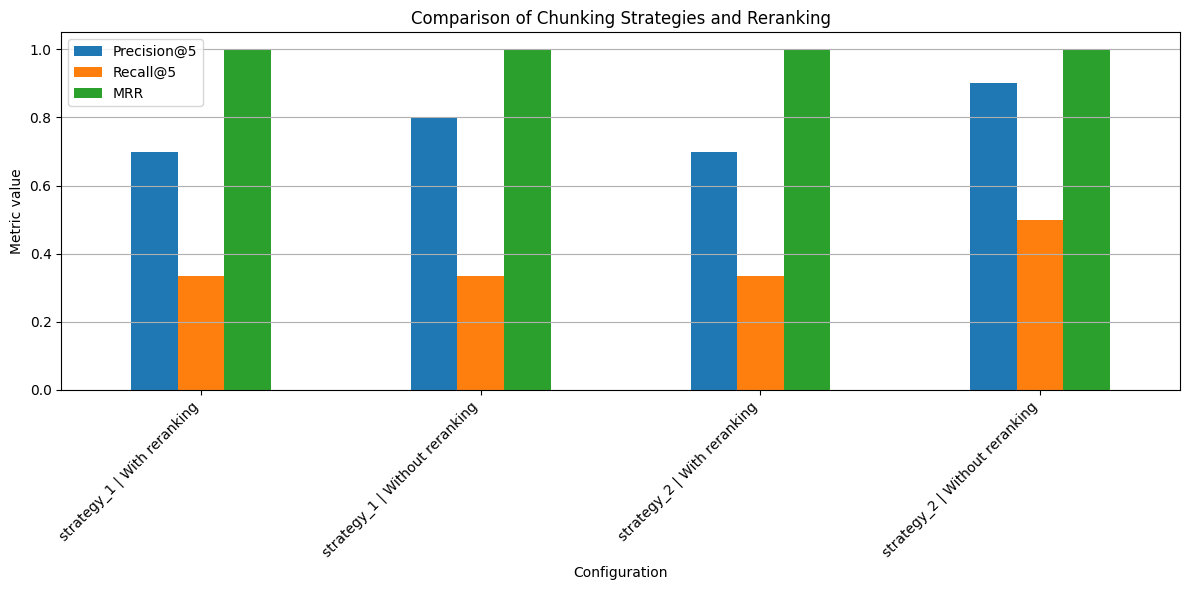

Retrieval comparison figure saved to:
/content/hw10_retrieval_comparison.png


In [29]:
# ============================================================
# Plot Chunking and Reranking Comparisons
# ============================================================

metrics_to_plot = [
    "Precision@5",
    "Recall@5",
    "MRR"
]

plot_data = summary_metrics_table.copy()

plot_data["Configuration"] = (
    plot_data["Strategy"]
    + " | "
    + plot_data["Approach"]
)

plot_data = plot_data.set_index("Configuration")

plot_data[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Comparison of Chunking Strategies and Reranking"
)
plt.ylabel("Metric value")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()

retrieval_comparison_figure_path = (
    "/content/hw10_retrieval_comparison.png"
)

plt.savefig(
    retrieval_comparison_figure_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Retrieval comparison figure saved to:")
print(retrieval_comparison_figure_path)

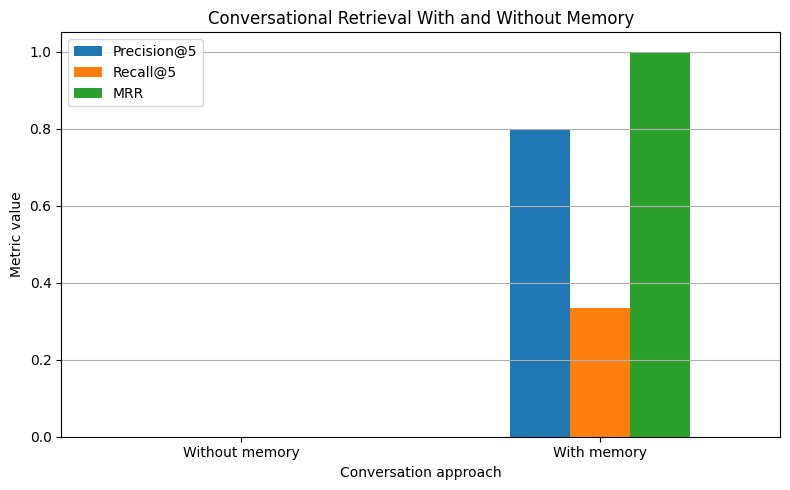

Memory comparison figure saved to:
/content/hw10_memory_comparison.png


In [30]:
# ============================================================
# Plot Conversational Memory Comparison
# ============================================================

memory_metrics_for_plot = memory_metrics_table.set_index(
    "Conversation approach"
)[
    [
        "Precision@5",
        "Recall@5",
        "MRR"
    ]
]

memory_metrics_for_plot.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title(
    "Conversational Retrieval With and Without Memory"
)
plt.ylabel("Metric value")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()

memory_comparison_figure_path = (
    "/content/hw10_memory_comparison.png"
)

plt.savefig(
    memory_comparison_figure_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Memory comparison figure saved to:")
print(memory_comparison_figure_path)

In [31]:
# ============================================================
# Generate Numerical Findings
# ============================================================

best_configuration = summary_metrics_table.loc[
    summary_metrics_table["MRR"].idxmax()
]

best_memory_configuration = memory_metrics_table.loc[
    memory_metrics_table["MRR"].idxmax()
]

print("Best overall retrieval configuration:")
print(
    "Strategy:",
    best_configuration["Strategy"]
)
print(
    "Approach:",
    best_configuration["Approach"]
)
print(
    f"Precision@5: "
    f"{best_configuration['Precision@5']:.4f}"
)
print(
    f"Recall@5: "
    f"{best_configuration['Recall@5']:.4f}"
)
print(
    f"MRR: "
    f"{best_configuration['MRR']:.4f}"
)

print("\nBest conversational-memory configuration:")
print(
    best_memory_configuration[
        "Conversation approach"
    ]
)
print(
    f"Precision@5: "
    f"{best_memory_configuration['Precision@5']:.4f}"
)
print(
    f"Recall@5: "
    f"{best_memory_configuration['Recall@5']:.4f}"
)
print(
    f"MRR: "
    f"{best_memory_configuration['MRR']:.4f}"
)

Best overall retrieval configuration:
Strategy: strategy_1
Approach: With reranking
Precision@5: 0.7000
Recall@5: 0.3333
MRR: 1.0000

Best conversational-memory configuration:
With memory
Precision@5: 0.8000
Recall@5: 0.3333
MRR: 1.0000


###Interpretation

The summary table provides the average Precision@5, Recall@5, and MRR for every combination of chunking strategy and reranking.

The bar chart makes it easier to compare whether:
- Smaller recursive chunks or larger sentence-aware chunks work better
- Reranking improves the initial vector retrieval
- The first relevant chunk appears earlier after reranking
The conversational-memory comparison shows whether adding the previous conversation context helps the system understand the second query. A higher MRR means that the first relevant result appears closer to rank 1.